# Copia de consulta — no editar ni usar para entrenar

Original: `notebooks/07_clasificacion_efficientnet.ipynb` · SHA-256 (UTF-8, saltos LF): `9cca3d97bac1d0a1e0ca19c75bcf849b10731a8e434b56708d057a74e92f42e4`.

Tipo: **consulta_guardada**. Fecha de ejecución/consulta: 2026-11-10T03:26:14.004649+00:00. Commit de ejecución: `92f76cf1e05f11a43be6d79a29c6e515d17f2721`.

Entorno de ejecución: `{"Pillow": "12.1.1", "figure_dpi": 55, "matplotlib": "3.10.8", "nbclient": "0.10.4", "numpy": "1.26.4", "pandas": "2.2.2", "python": "3.11.9", "scikit-learn": "1.7.2", "sistema": "Windows-10-10.0.26200-SP0"}`. Publicación: 2026-11-10T00:36:00-03:00. Commit de referencia del código: `92f76cf1e05f11a43be6d79a29c6e515d17f2721`.

Preparación del insumo: sin celdas omitidas.

Celdas ejecutadas (índices del original): [13]. Familia del test: no aplica.

Una consulta de corridas guardadas muestra resultados reales ya existentes; no reproduce los logs del entrenamiento. Val eligió checkpoints y se usa para reportar. Se quitaron widgets y formatos activos; en test se quitaron todas las imágenes.


<a href="https://colab.research.google.com/github/candeperles/PDI-TP/blob/main/notebooks/07_clasificacion_efficientnet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07. Clasificación con EfficientNetB0

Clasificación binaria: `0 = sin paneles`, `1 = con paneles`. La etiqueta se deriva de la presencia de al menos una caja YOLO. En `solarpanels_hd`, los IDs 0/1/2 son confianza de anotación, no tipos de panel (ver `docs/criterios_datos.md`).

Este notebook aplica la receta común del [issue #15](https://github.com/candeperles/PDI-TP/issues/15): entrada de **256×256**, batch **32**, Adam, dropout **0.3**, umbral **0.5** y semilla **42**. Se mantiene `aumentacion.google_maps` y se usan **pesos de muestra por fuente × clase**, calculados solo con train; no se aplica `class_weight`. EfficientNetB0 incluye su preprocesado y recibe píxeles en `[0, 255]`.

Se comparan tres modos:

- `imagenet_congelado`: pesos ImageNet y solo la cabeza entrenable; LR **1e-3**, hasta **30 épocas**, paciencia **10**.
- `imagenet_finetuning`: parte del **mejor `imagenet_congelado` guardado**, sin volver a entrenar la cabeza. Descongela todo el extractor salvo las BatchNorm, que conservan `trainable=False` y `training=False`; LR **1e-5**, hasta **20 épocas adicionales**, paciencia **10**.
- `aleatorio`: toda la red desde cero, incluidas las BatchNorm; LR **1e-3**, hasta **60 épocas**, paciencia **10** y `ReduceLROnPlateau` sobre `val_loss` (factor **0.5**, paciencia **3**). Las BatchNorm usan momentum **0.9** (Keras trae 0.99) para que sus promedios se estabilicen con los ~23 pasos por época del dataset, y el early stopping recién cuenta (y elige el mejor modelo) desde la época **20**.

Todos usan early stopping sobre `val_loss` con `restore_best_weights=True`. **Val se usa para elegir el checkpoint y para reportar: las métricas son optimistas.** El split compartido no cambia (738 train / 162 val).

En Colab, `entorno.preparar()` monta Drive. Cada modo se guarda completo apenas termina en `Mi unidad/PDI-TP/resultados/efficientnetb0/<modo>/`: `modelo.keras`, `historia.csv`, `metricas.json`, `predicciones_val.csv` y `config.json` con los parámetros reales. Las métricas las calcula únicamente `resultados.guardar_corrida`.


In [ ]:
# Preparar el entorno
import os, sys, json, subprocess
from pathlib import Path

SEMILLA = 42
os.environ['PYTHONHASHSEED'] = str(SEMILLA)

if 'google.colab' in sys.modules:
    repo = Path('/content/PDI-TP')
    if repo.is_dir():
        subprocess.run(['git', '-C', str(repo), 'pull', '--ff-only', '-q'], check=True)
    else:
        subprocess.run(['git', 'clone', '-q', 'https://github.com/candeperles/PDI-TP.git', str(repo)], check=True)
    # TensorFlow y versiones compatibles; no usar requirements.txt (su NumPy rompe TF).
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(repo / 'requirements-training.txt')],
                   check=True)
else:
    # Funciona al abrir Jupyter desde la raíz o desde notebooks/.
    repo = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pdi_tp' / 'entorno.py').is_file())
os.chdir(repo)
REPO = str(repo)
sys.path.insert(0, REPO)
from pdi_tp import aumentacion, clasificacion, entorno, resultados, split
rutas = entorno.preparar()
print('Repositorio:', REPO)
print('Imágenes:', rutas.imagenes)


In [ ]:
# Dependencias
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(SEMILLA)
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))


In [ ]:
# Receta común del issue #15
TAMANO_IMAGEN = 256
TAMANO_LOTE = 32
DROPOUT = 0.3
UMBRAL = 0.5
MODELO = 'efficientnetb0'
REPETIR = False  # Usar True en la primera corrida con esta receta para archivar las anteriores.

# El orden importa: el fine-tuning carga el mejor modelo del primer modo.
EXPERIMENTOS = {
    'imagenet_congelado': {
        'pesos': 'imagenet', 'fine_tuning': False,
        'lr': 1e-3, 'epocas_max': 30, 'paciencia': 10, 'reducir_lr': None,
        'momentum_batchnorm': None, 'inicio_parada': 0,
    },
    'imagenet_finetuning': {
        'pesos': 'imagenet', 'fine_tuning': True,
        'lr': 1e-5, 'epocas_max': 20, 'paciencia': 10, 'reducir_lr': None,
        'momentum_batchnorm': None, 'inicio_parada': 0,
    },
    'aleatorio': {
        'pesos': None, 'fine_tuning': False,
        'lr': 1e-3, 'epocas_max': 60, 'paciencia': 10,
        'reducir_lr': {'monitor': 'val_loss', 'factor': 0.5, 'paciencia': 3},
        # BatchNorm desde cero con momentum 0.9 y early stopping que cuenta desde la época 20.
        'momentum_batchnorm': 0.9, 'inicio_parada': 20,
    },
}


In [ ]:
# Split fijo y etiquetas binarias
def preparar_lista(archivos):
    nombres = [Path(archivo).name for archivo in archivos]
    imagenes = [str(rutas.imagenes / nombre) for nombre in nombres]
    etiquetas = [int((rutas.labels / f'{Path(nombre).stem}.txt').read_text().strip() != '')
                 for nombre in nombres]
    fuentes = [split.fuente(Path(nombre).stem) for nombre in nombres]
    return np.array(imagenes), np.array(etiquetas, dtype=np.float32), np.array(fuentes)

division = split.cargar_split(rutas)
archivos_entrenamiento, y_entrenamiento, fuentes_entrenamiento = preparar_lista(division['train'])
archivos_validacion, y_validacion, fuentes_validacion = preparar_lista(division['val'])
print('Train:', len(archivos_entrenamiento), 'positivos:', int(y_entrenamiento.sum()))
print('Val:', len(archivos_validacion), 'positivos:', int(y_validacion.sum()))

# Los pesos de muestra balancean fuente × clase solo en train. Val no se pondera.
pesos_entrenamiento = clasificacion.pesos_muestra_fuente_clase(fuentes_entrenamiento, y_entrenamiento)
pesos_validacion = np.ones(len(y_validacion), dtype=np.float32)


In [ ]:
# Datasets: EfficientNet espera píxeles en [0, 255], sin dividir por 255.
AUTOTUNE = tf.data.AUTOTUNE

def cargar_imagen(archivo, etiqueta, peso):
    imagen = tf.io.read_file(archivo)
    imagen = tf.image.decode_png(imagen, channels=3)
    imagen = tf.image.resize(imagen, (TAMANO_IMAGEN, TAMANO_IMAGEN))
    return imagen, etiqueta, peso

def crear_dataset(archivos, etiquetas, pesos, entrenamiento=False):
    conjunto = tf.data.Dataset.from_tensor_slices((archivos, etiquetas, pesos))
    if entrenamiento:
        conjunto = conjunto.shuffle(len(archivos), seed=SEMILLA, reshuffle_each_iteration=True)
    conjunto = conjunto.map(cargar_imagen, num_parallel_calls=AUTOTUNE)
    if entrenamiento:
        conjunto = conjunto.map(lambda imagen, etiqueta, peso: (aumentacion.google_maps(imagen), etiqueta, peso),
                                num_parallel_calls=AUTOTUNE)
    return conjunto.batch(TAMANO_LOTE).prefetch(AUTOTUNE)

ds_entrenamiento = crear_dataset(archivos_entrenamiento, y_entrenamiento, pesos_entrenamiento, entrenamiento=True)
ds_validacion = crear_dataset(archivos_validacion, y_validacion, pesos_validacion)


In [ ]:
# Modelo, entrenamiento y parámetros que se registran
def construir_modelo(pesos, momentum_batchnorm=None):
    extractor = keras.applications.EfficientNetB0(
        include_top=False, weights=pesos, input_shape=(TAMANO_IMAGEN, TAMANO_IMAGEN, 3)
    )
    if momentum_batchnorm is not None:
        for capa in extractor.layers:
            if isinstance(capa, layers.BatchNormalization):
                capa.momentum = momentum_batchnorm
    extractor.trainable = pesos is None
    entradas = keras.Input(shape=(TAMANO_IMAGEN, TAMANO_IMAGEN, 3))
    # El preprocesado ya está integrado. Con ImageNet se preservan las estadísticas de BatchNorm.
    x = extractor(entradas, training=False) if pesos == 'imagenet' else extractor(entradas)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(DROPOUT)(x)
    salidas = layers.Dense(1, activation='sigmoid')(x)
    return keras.Model(entradas, salidas)

def parametros_corrida(config):
    return {
        'red': 'EfficientNetB0', 'receta': 'comun_v2', 'pesos': config['pesos'], 'fine_tuning': config['fine_tuning'],
        'img_size': TAMANO_IMAGEN, 'batch_size': TAMANO_LOTE, 'dropout': DROPOUT,
        'lr': config['lr'], 'epocas_max': config['epocas_max'], 'paciencia': config['paciencia'],
        'umbral': UMBRAL, 'semilla': SEMILLA, 'optimizador': 'Adam',
        'perdida': 'binary_crossentropy', 'monitor': 'val_loss', 'restore_best_weights': True,
        'augmentation': 'google_maps', 'sample_weight': 'igual_masa_por_fuente_x_clase',
        'preprocesado': 'integrado_en_EfficientNetB0_entrada_0_255',
        'batchnorm_entrenable': config['pesos'] is None,
        'extractor_entrenable': config['pesos'] is None or config['fine_tuning'],
        'reducir_lr': config['reducir_lr'],
        'momentum_batchnorm': config['momentum_batchnorm'], 'inicio_parada': config['inicio_parada'],
    }

def entrenar(config, carpeta_inicial=None):
    if config['fine_tuning']:
        # Carga los mejores pesos de la cabeza; no vuelve a entrenarla ni modifica su archivo.
        modelo = keras.models.load_model(carpeta_inicial / 'modelo.keras', compile=False)
        extractor = modelo.get_layer('efficientnetb0')
        extractor.trainable = True
        for capa in extractor.layers:
            if isinstance(capa, layers.BatchNormalization):
                capa.trainable = False
        # El grafo guardado conserva extractor(entradas, training=False).
    else:
        modelo = construir_modelo(config['pesos'], config['momentum_batchnorm'])

    # Recompilar después de cambiar trainable, con un optimizador nuevo para cada modo.
    modelo.compile(optimizer=keras.optimizers.Adam(config['lr']), loss='binary_crossentropy',
                   metrics=[keras.metrics.BinaryAccuracy(name='accuracy', threshold=UMBRAL)])
    callbacks = [keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=config['paciencia'], restore_best_weights=True,
        start_from_epoch=config['inicio_parada'])]
    if config['reducir_lr'] is not None:
        reduccion = config['reducir_lr']
        callbacks.append(keras.callbacks.ReduceLROnPlateau(
            monitor=reduccion['monitor'], factor=reduccion['factor'], patience=reduccion['paciencia']))
    historia = modelo.fit(ds_entrenamiento, validation_data=ds_validacion,
                          epochs=config['epocas_max'], callbacks=callbacks)
    return modelo, historia


## Entrenamiento y guardado por modo

**Primera ejecución con la receta nueva:** cambiar `REPETIR = True`. Las corridas anteriores se archivan, no se borran. Después volver a `False` para saltear modos completos si se corta Colab. El fine-tuning exige que el modo congelado esté completo y tenga esta misma receta; si detecta una receta anterior, pide repetirla.

Se libera la sesión de Keras antes de cada modo para no mantener tres redes en la GPU. Cada corrida se guarda y valida antes de pasar a la siguiente. Si se interrumpe un modo posterior, los anteriores ya quedan completos en Drive.

Este cambio de código **no implica que la receta nueva ya se haya entrenado**. Las métricas reales se obtienen al ejecutar en Colab con GPU T4. Val elige los mejores pesos y también se usa para reportar.


In [ ]:
def ejecutar_experimentos():
    metricas_por_modo = {}
    historias = {}
    for nombre, config in EXPERIMENTOS.items():
        carpeta = resultados.ruta_corrida(rutas, MODELO, nombre)
        if resultados.corrida_completa(carpeta) and not REPETIR:
            print('Ya guardado, se saltea:', carpeta)
            continue

        carpeta_inicial = None
        if config['fine_tuning']:
            carpeta_inicial = resultados.ruta_corrida(rutas, MODELO, 'imagenet_congelado')
            if not resultados.corrida_completa(carpeta_inicial):
                raise RuntimeError('Completar imagenet_congelado antes del fine-tuning.')
            guardados = json.loads((carpeta_inicial / 'config.json').read_text(encoding='utf-8'))['params']
            esperados = parametros_corrida(EXPERIMENTOS['imagenet_congelado'])
            if any(guardados.get(clave) != valor for clave, valor in esperados.items()):
                raise ValueError('imagenet_congelado usa otra receta. Ejecutar con REPETIR = True para archivarla y repetirla.')

        carpeta = resultados.carpeta_corrida(rutas, MODELO, nombre, reiniciar=REPETIR)
        print('\n===', nombre, '===')
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEMILLA)
        modelo, historia = entrenar(config, carpeta_inicial)
        modelo.save(carpeta / 'modelo.keras')
        pd.DataFrame(historia.history).to_csv(carpeta / 'historia.csv', index_label='epoca')
        probabilidad = modelo.predict(ds_validacion, verbose=0).ravel()
        params = parametros_corrida(config)
        params['epocas_ejecutadas'] = len(historia.history['loss'])
        if carpeta_inicial is not None:
            params['corrida_inicial'] = f'{MODELO}/imagenet_congelado'
        metricas_por_modo[nombre] = resultados.guardar_corrida(
            rutas, carpeta, archivos=archivos_validacion, probabilidad=probabilidad,
            params=params, umbral=UMBRAL,
        )
        historias[nombre] = historia.history
        del modelo, historia
    return metricas_por_modo, historias

metricas_efficientnet, historias = ejecutar_experimentos()


In [ ]:
# Comparar solo resultados reales del formato común, incluidos los modos que se saltearon.
print('Val se usa para elegir el checkpoint y para reportar: las métricas son optimistas.')
corridas = resultados.cargar_corridas(rutas)
corridas[corridas['modelo'] == MODELO]


In [ ]:
# Curvas de los modos entrenados en esta sesión
import matplotlib.pyplot as plt

if historias:
    figura, ejes = plt.subplots(1, 2, figsize=(13, 4))
    for nombre, historia in historias.items():
        ejes[0].plot(historia['loss'], label=nombre)
        ejes[1].plot(historia['val_accuracy'], label=nombre)
    ejes[0].set_title('Pérdida'); ejes[0].set_xlabel('Época'); ejes[0].legend()
    ejes[1].set_title('Accuracy de validación'); ejes[1].set_xlabel('Época'); ejes[1].legend()
    plt.show()
else:
    print('No se entrenaron modos nuevos en esta sesión.')


## Consultar las corridas guardadas sin entrenar
Esta celda es independiente, no requiere GPU y abre los resultados en solo lectura. En Colab requiere haber clonado el repo y agregado el acceso directo a PDI-TP. La copia publicada ejecuta únicamente esta consulta, sin reproducir los logs originales.


Dataset:    C:\Users\cande\PDI-TP\data\grupo_5 (900 imágenes)
Resultados: C:\Users\cande\PDI-TP\resultados_locales\resultados (se crea al guardar un modelo)
GPU:        no hay GPU NVIDIA (corriendo en local)


Consulta de corridas guardadas. No se volvió a entrenar ni a predecir.
Val eligió checkpoints y se usa para reportar; Jamaica es un subconjunto de val.


,modelo,modo,fecha,completa,f1_macro,balanced_accuracy,recall,recall_sin_paneles,roc_auc,jamaica.f1_macro
0,efficientnetb0,aleatorio,2026-11-02T20:00:36,True,0.345963,0.590845,0.281690,0.90,0.562676,0.580122
1,efficientnetb0,imagenet_congelado,2026-11-02T19:49:53,True,0.699520,0.790493,0.830986,0.75,0.896831,0.780952
2,efficientnetb0,imagenet_finetuning,2026-11-02T19:54:06,True,0.778927,0.847183,0.894366,0.80,0.926761,0.825758



efficientnetb0/imagenet_congelado · fecha original: 2026-11-02T19:49:53 · commit: c32fad17f1b49755fd2c06271ec6872bd9692e24
SHA-256 de las fuentes consultadas:
config.json 2000824c62d6d668a9f68e3666879fff4edbf59ccd80054936b44c439f12a041
metricas.json 477d00dfd73964eef0172c001604d9b5d86e4093e89b5cf2e29b921d7d8c8573
predicciones_val.csv 8a9fe4fba2864ffaecf3ab2fe2cee6bfd1869fa611709ae7333344c93387e1dc


,modelo,modo,fecha,commit,sin_pesos,params.red,params.receta,params.pesos,params.fine_tuning,params.img_size,...,params.restore_best_weights,params.augmentation,params.sample_weight,params.preprocesado,params.batchnorm_entrenable,params.extractor_entrenable,params.reducir_lr,params.momentum_batchnorm,params.inicio_parada,params.epocas_ejecutadas
0,efficientnetb0,imagenet_congelado,2026-11-02T19:49:53,c32fad17f1b49755fd2c06271ec6872bd9692e24,False,EfficientNetB0,comun_v2,imagenet,False,256,...,True,google_maps,igual_masa_por_fuente_x_clase,integrado_en_EfficientNetB0_entrada_0_255,False,False,None,None,0,30


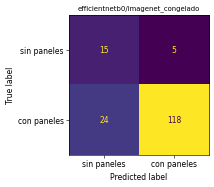

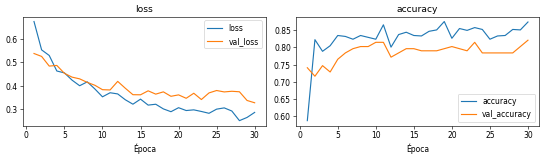


efficientnetb0/imagenet_finetuning · fecha original: 2026-11-02T19:54:06 · commit: c32fad17f1b49755fd2c06271ec6872bd9692e24
SHA-256 de las fuentes consultadas:
config.json 64ab35ea53a8c4f2f0b0ed138b700181295faa92b50fb0ecc328749b1fd5997b
metricas.json caafa1ade932a54145aa10cff83248230921f1637e9ed46665fe47b0e23f06a7
predicciones_val.csv 75875d605d1b1073dfbae470959f140101118da5c568df75208d39a53645b55b


,modelo,modo,fecha,commit,sin_pesos,params.red,params.receta,params.pesos,params.fine_tuning,params.img_size,...,params.augmentation,params.sample_weight,params.preprocesado,params.batchnorm_entrenable,params.extractor_entrenable,params.reducir_lr,params.momentum_batchnorm,params.inicio_parada,params.epocas_ejecutadas,params.corrida_inicial
0,efficientnetb0,imagenet_finetuning,2026-11-02T19:54:06,c32fad17f1b49755fd2c06271ec6872bd9692e24,False,EfficientNetB0,comun_v2,imagenet,True,256,...,google_maps,igual_masa_por_fuente_x_clase,integrado_en_EfficientNetB0_entrada_0_255,False,True,None,None,0,20,efficientnetb0/imagenet_congelado


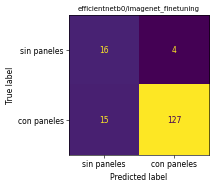

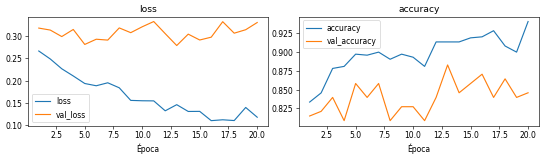


efficientnetb0/aleatorio · fecha original: 2026-11-02T20:00:36 · commit: c32fad17f1b49755fd2c06271ec6872bd9692e24
SHA-256 de las fuentes consultadas:
config.json 023856f1e9cb13e5721131545d8898e8faeb3f71105652f19e8072d124fc8ac5
metricas.json 381579e96b98416592c063739e29985f2acf36e27187d1690d3c614cc2ba7356
predicciones_val.csv fc0e3be380d3fa4d275b1eaddc22de459c7dd7f6ee6657c605721829e6d51ab6


,modelo,modo,fecha,commit,sin_pesos,params.red,params.receta,params.pesos,params.fine_tuning,params.img_size,...,params.sample_weight,params.preprocesado,params.batchnorm_entrenable,params.extractor_entrenable,params.reducir_lr.monitor,params.reducir_lr.factor,params.reducir_lr.paciencia,params.momentum_batchnorm,params.inicio_parada,params.epocas_ejecutadas
0,efficientnetb0,aleatorio,2026-11-02T20:00:36,c32fad17f1b49755fd2c06271ec6872bd9692e24,False,EfficientNetB0,comun_v2,None,False,256,...,igual_masa_por_fuente_x_clase,integrado_en_EfficientNetB0_entrada_0_255,True,True,val_loss,0.5,3,0.9,20,37


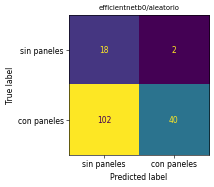

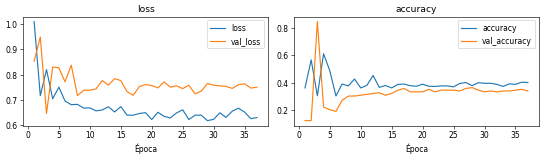

In [1]:
# Consulta independiente: ejecutar solo esta celda para mostrar resultados guardados.
# Las celdas de entrenamiento de arriba no se ejecutan en la copia publicada.
import sys
from pathlib import Path
raiz_consulta = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "pdi_tp" / "lectura_entrega.py").is_file()), None)
if raiz_consulta is None:
    raise FileNotFoundError("Abrí el notebook desde el repositorio clonado.")
sys.path.insert(0, str(raiz_consulta))
from pdi_tp import lectura_entrega
lectura_entrega.mostrar_modelo("efficientnetb0")
